# MNIST Handwritten Digit Classification

This project uses an Artificial Neural Network (ANN) built with PyTorch to classify handwritten digits from 0 to 9.

The model is trained on the MNIST training dataset and evaluated on the official MNIST test dataset.

In [5]:
!pip install idx2numpy

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for idx2numpy: filename=idx2numpy-1.2.3-py3-none-any.whl size=8001 sha256=148f03aaa9b76ee603500e093cc9e70454392490906ae7ce4f71106bb518d35d
  Stored in directory: /root/.cache/pip/wheels/3a/19/2b/d62d9c881cc383ad62fc12a882040d1900c19b5115b6a41e50
Successfully built idx2numpy


In [6]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import idx2numpy

from PIL import Image
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from torch.utils.data import Dataset, DataLoader

In [7]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cpu


In [8]:
!wget -nc https://storage.googleapis.com/cvdf-datasets/mnist/train-images-idx3-ubyte.gz
!wget -nc https://storage.googleapis.com/cvdf-datasets/mnist/train-labels-idx1-ubyte.gz

!wget -nc https://storage.googleapis.com/cvdf-datasets/mnist/t10k-images-idx3-ubyte.gz
!wget -nc https://storage.googleapis.com/cvdf-datasets/mnist/t10k-labels-idx1-ubyte.gz

--2026-11-03 18:08:48--  https://storage.googleapis.com/cvdf-datasets/mnist/train-images-idx3-ubyte.gz
Resolving storage.googleapis.com (storage.googleapis.com)... 142.250.98.207, 142.251.107.207, 2607:f8b0:400c:c32::cf
Connecting to storage.googleapis.com (storage.googleapis.com)|142.250.98.207|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 9912422 (9.5M) [application/x-gzip]
Saving to: ‘train-images-idx3-ubyte.gz’

train-images-idx3-u 100%[===================>]   9.45M  28.9MB/s    in 0.3s    

2026-11-03 18:08:48 (28.9 MB/s) - ‘train-images-idx3-ubyte.gz’ saved [9912422/9912422]

--2026-11-03 18:08:48--  https://storage.googleapis.com/cvdf-datasets/mnist/train-labels-idx1-ubyte.gz
Resolving storage.googleapis.com (storage.googleapis.com)... 142.250.98.207, 142.251.107.207, 2607:f8b0:400c:c32::cf
Connecting to storage.googleapis.com (storage.googleapis.com)|142.250.98.207|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 28881 (28K) 

In [9]:
!gunzip -kf train-images-idx3-ubyte.gz
!gunzip -kf train-labels-idx1-ubyte.gz

!gunzip -kf t10k-images-idx3-ubyte.gz
!gunzip -kf t10k-labels-idx1-ubyte.gz

In [10]:
X_train = idx2numpy.convert_from_file(
    "/content/train-images-idx3-ubyte"
)

y_train = idx2numpy.convert_from_file(
    "/content/train-labels-idx1-ubyte"
)

X_test = idx2numpy.convert_from_file(
    "/content/t10k-images-idx3-ubyte"
)

y_test = idx2numpy.convert_from_file(
    "/content/t10k-labels-idx1-ubyte"
)

print("Training Images:", X_train.shape)
print("Training Labels:", y_train.shape)

print("Testing Images:", X_test.shape)
print("Testing Labels:", y_test.shape)

Training Images: (60000, 28, 28)
Training Labels: (60000,)
Testing Images: (10000, 28, 28)
Testing Labels: (10000,)


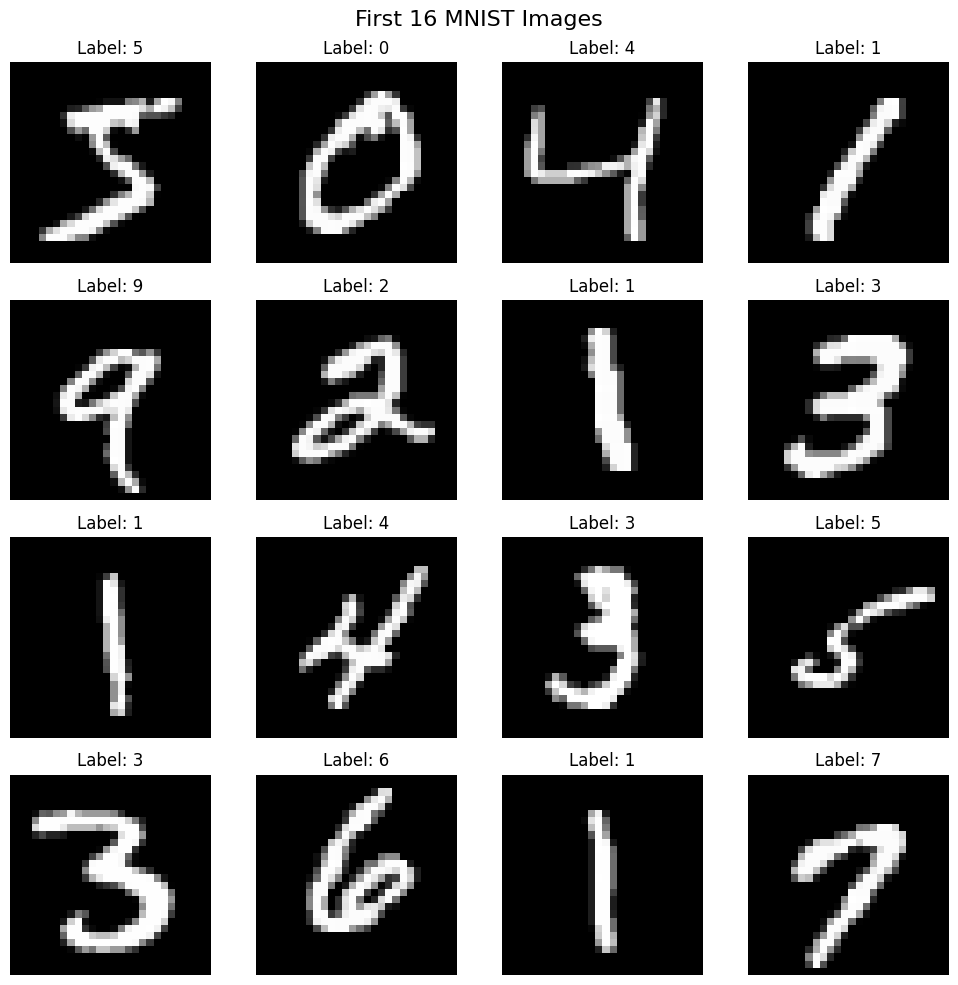

In [11]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))

fig.suptitle("First 16 MNIST Images", fontsize=16)

for i, ax in enumerate(axes.flat):

    ax.imshow(X_train[i], cmap="gray")
    ax.set_title(f"Label: {y_train[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [12]:
X_train = X_train.reshape(60000, 784).astype(np.float32) / 255.0

X_test = X_test.reshape(10000, 784).astype(np.float32) / 255.0

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (60000, 784)
X_test: (10000, 784)


In [13]:
class CustomDataset(Dataset):

    def __init__(self, features, labels):

        self.features = torch.tensor(
            features, dtype=torch.float32
        )

        self.labels = torch.tensor(
            labels, dtype=torch.long
        )

    def __len__(self):
        return len(self.features)

    def __getitem__(self, index):

        return self.features[index], self.labels[index]

In [14]:
train_dataset = CustomDataset(X_train, y_train)

test_dataset = CustomDataset(X_test, y_test)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    pin_memory=(device.type == "cuda")
)

In [15]:
class MyNN(nn.Module):

    def __init__(self, num_features):

        super().__init__()

        self.model = nn.Sequential(

            nn.Linear(num_features, 128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, 10)
        )

    def forward(self, x):

        return self.model(x)

In [16]:
model = MyNN(784).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.SGD(
    model.parameters(),
    lr=0.01
)

epochs = 10

print(model)

MyNN(
  (model): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [17]:
for epoch in range(epochs):

    model.train()

    total_epoch_loss = 0

    for batch_features, batch_labels in train_loader:

        batch_features = batch_features.to(device)
        batch_labels = batch_labels.to(device)

        outputs = model(batch_features)

        loss = criterion(outputs, batch_labels)

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        total_epoch_loss += loss.item() * batch_labels.size(0)

    avg_loss = total_epoch_loss / len(train_dataset)

    print(
        f"Epoch [{epoch+1}/{epochs}], "
        f"Loss: {avg_loss:.4f}"
    )

Epoch [1/10], Loss: 1.7118
Epoch [2/10], Loss: 0.5772
Epoch [3/10], Loss: 0.4031
Epoch [4/10], Loss: 0.3473
Epoch [5/10], Loss: 0.3142
Epoch [6/10], Loss: 0.2897
Epoch [7/10], Loss: 0.2704
Epoch [8/10], Loss: 0.2539
Epoch [9/10], Loss: 0.2390
Epoch [10/10], Loss: 0.2255


In [18]:
def evaluate_model(model, loader):

    model.eval()

    total = 0
    correct = 0
    total_loss = 0

    with torch.no_grad():

        for batch_features, batch_labels in loader:

            batch_features = batch_features.to(device)
            batch_labels = batch_labels.to(device)

            outputs = model(batch_features)

            loss = criterion(outputs, batch_labels)

            _, predicted = torch.max(outputs, 1)

            total += batch_labels.size(0)

            correct += (predicted == batch_labels).sum().item()

            total_loss += loss.item() * batch_labels.size(0)

    accuracy = correct / total

    avg_loss = total_loss / total

    return avg_loss, accuracy

In [19]:
train_loss, train_accuracy = evaluate_model(
    model, train_loader
)

test_loss, test_accuracy = evaluate_model(
    model, test_loader
)

print("Train Loss:", round(train_loss, 4))
print("Test Loss:", round(test_loss, 4))

print("Train Accuracy:", f"{train_accuracy * 100:.2f}%")
print("Test Accuracy:", f"{test_accuracy * 100:.2f}%")

Train Loss: 0.2171
Test Loss: 0.2143
Train Accuracy: 93.83%
Test Accuracy: 93.82%


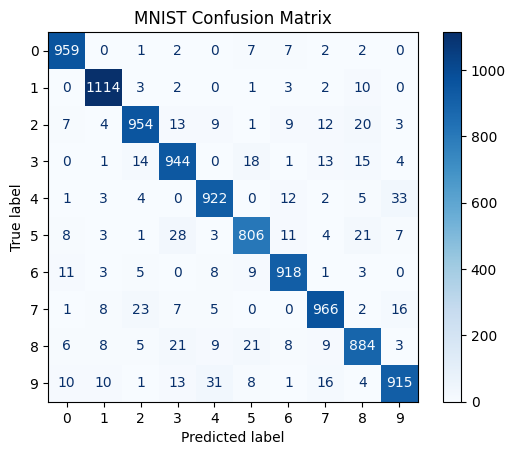

In [20]:
all_preds = []
all_labels = []

model.eval()

with torch.no_grad():

    for batch_features, batch_labels in test_loader:

        batch_features = batch_features.to(device)

        outputs = model(batch_features)

        _, predicted = torch.max(outputs, 1)

        all_preds.extend(predicted.cpu().numpy())

        all_labels.extend(batch_labels.numpy())

cm = confusion_matrix(all_labels, all_preds)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

disp.plot(cmap="Blues")

plt.title("MNIST Confusion Matrix")

plt.show()

In [21]:
torch.save(
    model.state_dict(),
    "/content/mnist_model.pth"
)

print("Model saved successfully!")

Model saved successfully!


In [22]:
loaded_model = MyNN(784).to(device)

loaded_model.load_state_dict(
    torch.load(
        "/content/mnist_model.pth",
        map_location=device
    )
)

loaded_model.eval()

print("Model loaded successfully!")

Model loaded successfully!


In [23]:
sample = torch.tensor(
    X_test[0],
    dtype=torch.float32
).unsqueeze(0).to(device)

with torch.no_grad():

    output = loaded_model(sample)

    predicted = torch.argmax(output, dim=1)

print("Predicted:", predicted.item())
print("Actual:", int(y_test[0]))

Predicted: 7
Actual: 7


Saving 3pic.jpeg to 3pic (2).jpeg


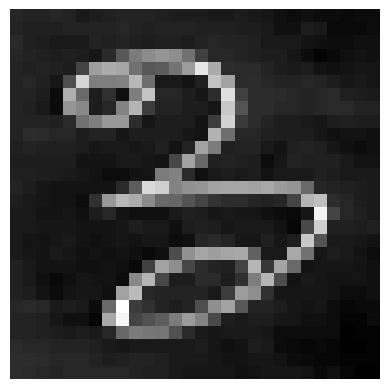

Predicted Digit: 3
Confidence: 63.66%


In [27]:
from google.colab import files

uploaded = files.upload()

image_path = next(iter(uploaded))

img = Image.open(image_path).convert("L")

img = img.resize((28, 28))

img_array = np.array(img)

# Invert white background to black
img_array = 255 - img_array

# Normalize
img_array = img_array.astype(np.float32) / 255.0

# Display image
plt.imshow(img_array, cmap="gray")
plt.axis("off")
plt.show()

# Convert to tensor
sample = torch.tensor(
    img_array.reshape(1, 784),
    dtype=torch.float32
).to(device)

# Prediction
loaded_model.eval()

with torch.no_grad():

    output = loaded_model(sample)

    probabilities = torch.softmax(output, dim=1)

    confidence, predicted = torch.max(probabilities, dim=1)

print("Predicted Digit:", predicted.item())

print(
    "Confidence:",
    f"{confidence.item() * 100:.2f}%"
)